# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Maulana Dwi Prasetya
- NIM   : 241011400102
- Kelas : Reg B


## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [16]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2 digit terakhir NIM 241011400102 adalah 02 -> RANDOM_STATE = 2
RANDOM_STATE = 2
print(f"RANDOM_STATE diset ke: {RANDOM_STATE}")


RANDOM_STATE diset ke: 2


In [17]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

=== 5 Data Pertama Ads_Data.csv ===


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah total baris data: 40

Shape X: (40, 1) (2 dimensi)
Shape y: (40,) (1 dimensi)


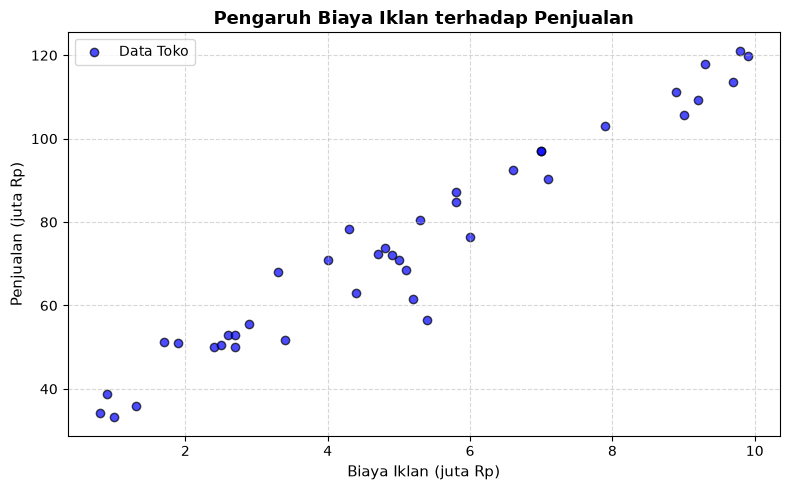

In [18]:
# Jawaban A1
# 1. Baca Ads_Data.csv dan tampilkan 5 data pertama serta jumlah barisnya
ads_data = pd.read_csv('Ads_Data.csv')
print("=== 5 Data Pertama Ads_Data.csv ===")
display(ads_data.head())
print(f"Jumlah total baris data: {len(ads_data)}")

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan), pastikan X berbentuk 2 dimensi (n, 1)
X = ads_data[['BiayaIklan']].values
y = ads_data['Penjualan'].values
print(f"\nShape X: {X.shape} (2 dimensi)")
print(f"Shape y: {y.shape} (1 dimensi)")

# 3. Buat scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', edgecolors='black', alpha=0.7, label='Data Toko')
plt.title('Pengaruh Biaya Iklan terhadap Penjualan', fontsize=13, fontweight='bold')
plt.xlabel('Biaya Iklan (juta Rp)', fontsize=11)
plt.ylabel('Penjualan (juta Rp)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [19]:
# Jawaban A2
# Bagi data menjadi training dan testing (80:20) dengan random_state=2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

# Tampilkan shape masing-masing
print("=== Ukuran Data Training dan Testing ===")
print(f"Shape X_train : {X_train.shape}")
print(f"Shape X_test  : {X_test.shape}")
print(f"Shape y_train : {y_train.shape}")
print(f"Shape y_test  : {y_test.shape}")


=== Ukuran Data Training dan Testing ===
Shape X_train : (32, 1)
Shape X_test  : (8, 1)
Shape y_train : (32,)
Shape y_test  : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [20]:
# Jawaban A3
# 1. Implementasi LinearRegression menggunakan Normal Equation dari materi
class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_

# Latih model dengan data training
regressor = LinearRegression()
regressor.fit(X_train, y_train)

# 2. Tampilkan nilai intercept dan koefisien serta persamaan garis regresi
b = regressor.intercept_
m = regressor.coefficients_[0]

print("=== Hasil Training Normal Equation ===")
print(f"Intercept (b)  : {b:.4f}")
print(f"Koefisien (m)  : {m:.4f}")
print(f"\nPersamaan Garis Regresi:")
print(f"y_hat = {b:.4f} + {m:.4f} * X")
print(f"Penjualan = {b:.4f} + {m:.4f} * BiayaIklan")


=== Hasil Training Normal Equation ===
Intercept (b)  : 29.8087
Koefisien (m)  : 8.8424

Persamaan Garis Regresi:
y_hat = 29.8087 + 8.8424 * X
Penjualan = 29.8087 + 8.8424 * BiayaIklan


**Jawaban A3 (interpretasi):**

Berdasarkan hasil perhitungan model Linear Regression menggunakan Normal Equation:
1. **Nilai Intercept ($b = 29.8087$):** Menunjukkan bahwa jika toko online tidak mengeluarkan biaya iklan sama sekali ($X = 0$ juta Rp), maka perkiraan penjualan dasar yang diperoleh adalah sekitar **29.81 juta Rp**. Ini mencerminkan penjualan organik toko tanpa promosi berbayar.
2. **Nilai Koefisien ($m = 8.8424$):** Bernilai positif, yang berarti ada hubungan searah yang kuat antara biaya iklan dan penjualan. Artinya, **setiap kenaikan biaya iklan sebesar 1 juta Rp, maka penjualan toko diperkirakan akan meningkat rata-rata sebesar 8.84 juta Rp**.


### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [21]:
# Jawaban A4
# Implementasi fungsi metrik evaluasi regresi dengan NumPy
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

# Hitung prediksi pada data training dan testing
y_train_pred = regressor.predict(X_train)
y_test_pred = regressor.predict(X_test)

# Hitung semua metrik
metrics_data = {
    'Metrik': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Training Data': [
        mae(y_train, y_train_pred),
        mse(y_train, y_train_pred),
        rmse(y_train, y_train_pred),
        r2(y_train, y_train_pred)
    ],
    'Testing Data': [
        mae(y_test, y_test_pred),
        mse(y_test, y_test_pred),
        rmse(y_test, y_test_pred),
        r2(y_test, y_test_pred)
    ]
}

df_metrics = pd.DataFrame(metrics_data)
df_metrics['Training Data'] = df_metrics['Training Data'].round(4)
df_metrics['Testing Data'] = df_metrics['Testing Data'].round(4)
display(df_metrics)


,Metrik,Training Data,Testing Data
0,MAE,4.3984,5.3907
1,MSE,37.8849,31.5270
2,RMSE,6.1551,5.6149
3,R²,0.9342,0.9601


**Jawaban A4 (analisis):**

Dari tabel evaluasi di atas, berikut analisis terhadap performa model:
1. **Arti Nilai RMSE:** 
   - Nilai RMSE pada data training adalah **6.1551 juta Rp** dan pada data testing adalah **5.6149 juta Rp**.
   - RMSE mengukur rata-rata besaran simpangan atau error prediksi model terhadap data aktual dalam satuan yang sama (juta Rp). Artinya, prediksi penjualan oleh model rata-rata meleset sekitar 5.61 juta Rp pada data testing. Nilai error ini tergolong relatif kecil jika dibandingkan dengan rentang nilai penjualan toko yang berkisar antara 33 hingga 121 juta Rp.
2. **Arti Nilai $R^2$:** 
   - Nilai $R^2$ pada data training adalah **0.9342 (93.42%)** dan pada data testing adalah **0.9601 (96.01%)**.
   - Artinya, sebesar **96.01% variasi penjualan pada data testing dapat dijelaskan dengan sangat baik oleh variabel biaya iklan** melalui model linear ini, sedangkan sisanya (sekitar 3.99%) dipengaruhi oleh faktor lain di luar biaya iklan.
3. **Kesimpulan Kualitas Model:**
   - Model ini **sangat baik**. Nilai $R^2$ di atas 0.93 pada kedua dataset menunjukkan korelasi linear yang sangat kuat. Selain itu, nilai evaluasi pada data training dan testing sangat seimbang (bahkan performa pada testing sedikit lebih baik), yang menandakan bahwa model tidak mengalami overfitting maupun underfitting dan memiliki kemampuan generalisasi yang sangat solid.


### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

=== Perbandingan Gradient Descent vs Normal Equation ===
Normal Equation (A3) : Intercept = 29.8087, Koefisien = 8.8424
-----------------------------------------------------------------
Learning Rate 0.001: Intercept = 19.3390, Koefisien = 10.4472, Loss Akhir = 59.7947
Learning Rate 0.02 : Intercept = 29.8087, Koefisien = 8.8424, Loss Akhir = 37.8849
Learning Rate 0.1  : Intercept = NaN, Koefisien = NaN (Gagal Konvergen / Divergen)


/Users/user/Library/Python/3.13/lib/python/site-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/var/folders/5n/dlrz61b50g134bk3ttj28rk40000gn/T/ipykernel_53471/2253777164.py:27: RuntimeWarning: overflow encountered in square
  loss = np.mean((y - X_b @ beta) ** 2)
/var/folders/5n/dlrz61b50g134bk3ttj28rk40000gn/T/ipykernel_53471/2253777164.py:24: RuntimeWarning: overflow encountered in matmul
  gradient = X_b.T @ (y_hat - y) / len(y)
/var/folders/5n/dlrz61b50g134bk3ttj28rk40000gn/T/ipykernel_53471/2253777164.py:25: RuntimeWarning: invalid value encountered in subtract
  beta = beta - self.learning_rate * gradient


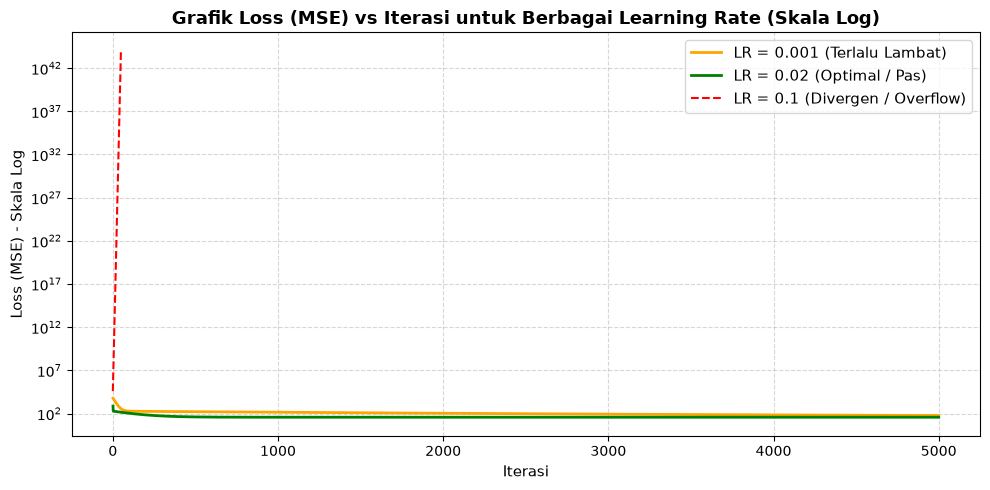

In [22]:
# Jawaban A5
# 1. Salin LinearRegressionGD dari materi
class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            y_hat = X_b @ beta
            gradient = X_b.T @ (y_hat - y) / len(y)
            beta = beta - self.learning_rate * gradient

            loss = np.mean((y - X_b @ beta) ** 2)
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_

# Latih dengan 3 learning rate berbeda
learning_rates = [0.001, 0.02, 0.1]
gd_models = {}

print("=== Perbandingan Gradient Descent vs Normal Equation ===")
print(f"Normal Equation (A3) : Intercept = {regressor.intercept_:.4f}, Koefisien = {regressor.coefficients_[0]:.4f}")
print("-" * 65)

for lr in learning_rates:
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    model.fit(X_train, y_train)
    gd_models[lr] = model
    if np.isnan(model.intercept_):
        print(f"Learning Rate {lr:<5}: Intercept = NaN, Koefisien = NaN (Gagal Konvergen / Divergen)")
    else:
        print(f"Learning Rate {lr:<5}: Intercept = {model.intercept_:.4f}, Koefisien = {model.coefficients_[0]:.4f}, Loss Akhir = {model.loss_history_[-1]:.4f}")

# 3. Buat grafik loss (MSE) vs iterasi
plt.figure(figsize=(10, 5))
iterations = range(1, 5001)

# Plot lr = 0.001 dan 0.02
plt.plot(iterations, gd_models[0.001].loss_history_, label='LR = 0.001 (Terlalu Lambat)', color='orange', linewidth=2)
plt.plot(iterations, gd_models[0.02].loss_history_, label='LR = 0.02 (Optimal / Pas)', color='green', linewidth=2)

# Plot lr = 0.1 (hanya bagian sebelum overflow jika ada)
loss_01 = np.array(gd_models[0.1].loss_history_)
valid_idx = np.where(~np.isnan(loss_01) & ~np.isinf(loss_01))[0]
if len(valid_idx) > 0:
    plt.plot(valid_idx[:50], loss_01[valid_idx[:50]], label='LR = 0.1 (Divergen / Overflow)', color='red', linestyle='--')

plt.yscale('log')
plt.title('Grafik Loss (MSE) vs Iterasi untuk Berbagai Learning Rate (Skala Log)', fontsize=13, fontweight='bold')
plt.xlabel('Iterasi', fontsize=11)
plt.ylabel('Loss (MSE) - Skala Log', fontsize=11)
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


**Jawaban A5 (analisis):**

Berdasarkan eksperimen Gradient Descent dengan 5000 iterasi pada 3 learning rate:
1. **Learning Rate 0.001 (Terlalu Lambat):**
   - Hasil akhir: Intercept = **19.3390**, Koefisien = **10.4472**, dengan loss akhir **59.7947**.
   - Nilai ini masih cukup jauh dari solusi optimal Normal Equation (b = 29.8087, m = 8.8424, loss = 37.8849).
   - *Penyebab:* Nilai learning rate terlalu kecil, sehingga langkah pembaruan bobot pada setiap iterasi sangat lambat. Dalam 5000 iterasi, model belum sempat mencapai titik minimum global (belum konvergen sempurna).
2. **Learning Rate 0.02 (Paling Pas / Optimal):**
   - Hasil akhir: Intercept = **29.8087**, Koefisien = **8.8424**, dengan loss akhir **37.8849**.
   - Hasil ini **identik persis** dengan hasil Normal Equation pada Soal A3. Pada grafik, loss turun dengan mulus dan stabil mencapai konvergensi.
   - *Penyebab:* Ukuran langkah gradien pas, tidak terlalu kecil dan tidak terlalu besar, sehingga berhasil menuruni permukaan error hingga tepat di lembah minimum global.
3. **Learning Rate 0.1 (Gagal Konvergen / Divergen):**
   - Hasil akhir: Intercept = **NaN**, Koefisien = **NaN**, dan muncul peringatan `RuntimeWarning: overflow`.
   - *Penyebab:* Nilai learning rate terlalu besar. Langkah pembaruan bobot melompat terlalu jauh melewati titik minimum (*overshooting*). Akibatnya, nilai gradien dan bobot semakin membesar secara eksponensial di setiap iterasi hingga melampaui batas representasi angka floating point komputer (overflow/infinity), yang akhirnya menghasilkan nilai `NaN`.


### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

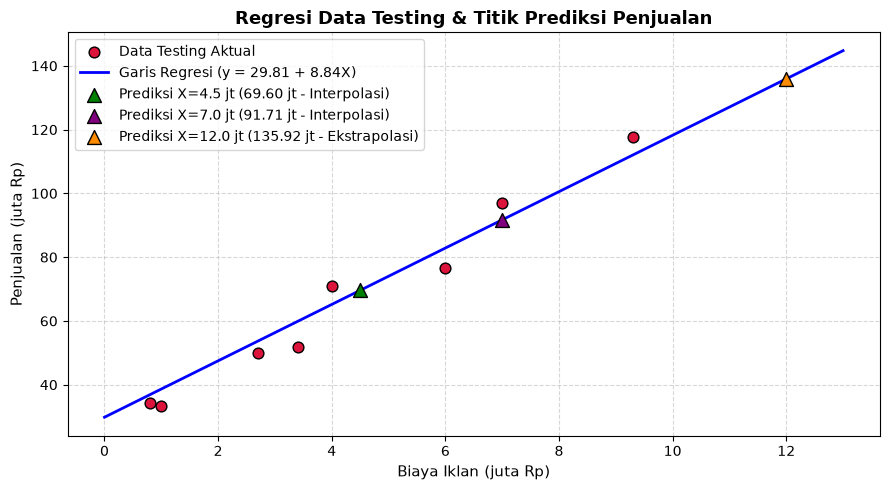

,Biaya Iklan (juta Rp),Prediksi Penjualan (juta Rp),Kategori Prediksi
0,4.5,69.5995,Interpolasi (Dalam Rentang Data)
1,7.0,91.7054,Interpolasi (Dalam Rentang Data)
2,12.0,135.9174,Ekstrapolasi (Di Luar Rentang Data)


In [23]:
# Jawaban A6
# 1. Scatter plot data testing beserta garis regresi dari model A3
plt.figure(figsize=(9, 5))
plt.scatter(X_test, y_test, color='crimson', s=60, edgecolors='black', label='Data Testing Aktual', zorder=3)

# Buat garis regresi
x_line = np.linspace(0, 13, 200).reshape(-1, 1)
y_line = regressor.predict(x_line)
plt.plot(x_line, y_line, color='blue', linewidth=2, label=f'Garis Regresi (y = {b:.2f} + {m:.2f}X)')

# 2. Prediksi untuk biaya iklan 4.5 juta, 7 juta, dan 12 juta
new_ads = np.array([[4.5], [7.0], [12.0]])
predicted_sales = regressor.predict(new_ads)

# Tandai titik prediksi pada plot
colors_pred = ['green', 'purple', 'darkorange']
for i, (val, pred) in enumerate(zip([4.5, 7.0, 12.0], predicted_sales)):
    status = 'Ekstrapolasi' if val == 12.0 else 'Interpolasi'
    plt.scatter(val, pred, color=colors_pred[i], s=100, marker='^', edgecolors='black', label=f'Prediksi X={val} jt ({pred:.2f} jt - {status})', zorder=4)

plt.title('Regresi Data Testing & Titik Prediksi Penjualan', fontsize=13, fontweight='bold')
plt.xlabel('Biaya Iklan (juta Rp)', fontsize=11)
plt.ylabel('Penjualan (juta Rp)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# Cetak hasil prediksi dalam tabel
df_pred = pd.DataFrame({
    'Biaya Iklan (juta Rp)': [4.5, 7.0, 12.0],
    'Prediksi Penjualan (juta Rp)': predicted_sales,
    'Kategori Prediksi': ['Interpolasi (Dalam Rentang Data)', 'Interpolasi (Dalam Rentang Data)', 'Ekstrapolasi (Di Luar Rentang Data)']
})
df_pred['Prediksi Penjualan (juta Rp)'] = df_pred['Prediksi Penjualan (juta Rp)'].round(4)
display(df_pred)


**Jawaban A6 (analisis):**

1. **Hasil Prediksi:**
   - Biaya iklan **4.5 juta Rp** menghasilkan prediksi penjualan sebesar **69.60 juta Rp**.
   - Biaya iklan **7.0 juta Rp** menghasilkan prediksi penjualan sebesar **91.71 juta Rp**.
   - Biaya iklan **12.0 juta Rp** menghasilkan prediksi penjualan sebesar **135.92 juta Rp**.

2. **Tingkat Kepercayaan Prediksi 12 Juta (Ekstrapolasi):**
   - Pada dataset `Ads_Data.csv`, rentang biaya iklan aktual hanya berkisar antara **0.8 juta sampai 9.9 juta Rp**.
   - Prediksi untuk biaya iklan **12 juta Rp** berada di luar rentang data historis tersebut, sehingga disebut sebagai **ekstrapolasi**.
   - **Tingkat kepercayaannya lebih rendah dan perlu diwaspadai**, karena:
     - Model linear mengasumsikan bahwa pola hubungan garis lurus akan terus berlanjut tanpa batas.
     - Dalam dunia bisnis nyata, penambahan biaya iklan biasanya mengalami fenomena *law of diminishing returns* (penurunan hasil marjinal), atau pasar bisa mengalami kejenuhan (*market saturation*). Penjualan tidak bisa naik tanpa batas secara linear murni.
     - Oleh karena itu, angka 135.92 juta Rp hanya dapat dianggap sebagai estimasi matematis teoretis, bukan kepastian riil. Untuk biaya 4.5 juta dan 7 juta (interpolasi), tingkat kepercayaannya sangat tinggi karena berada di dalam rentang data yang padat.


---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

=== 5 Data Pertama Email_Data.csv ===


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



=== Jumlah Email Spam dan Bukan Spam ===
Spam
Bukan Spam    35
Spam          25
Name: count, dtype: int64

Shape X_email: (60, 2)
Shape y_email: (60,)


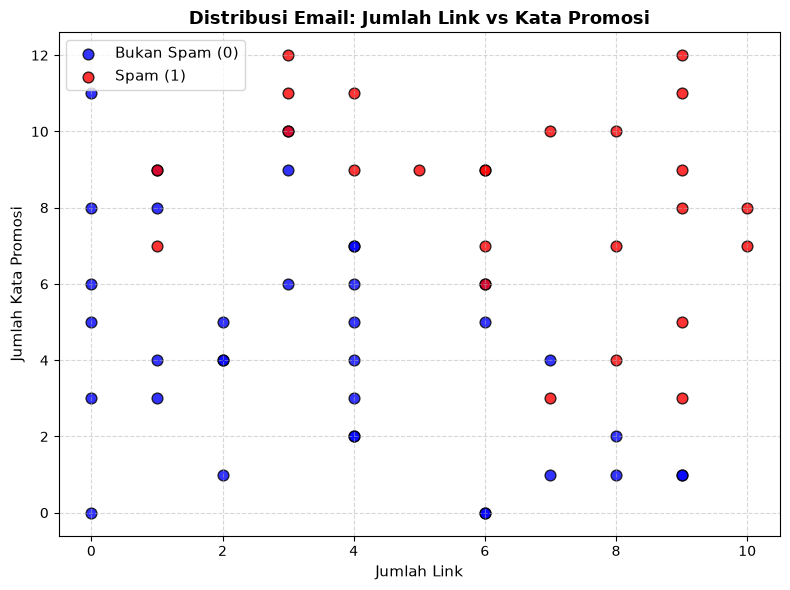

In [24]:
# Jawaban B1
# 1. Baca Email_Data.csv, tampilkan 5 data pertama, dan hitung jumlah Spam dan Bukan Spam
email_data = pd.read_csv('Email_Data.csv')
print("=== 5 Data Pertama Email_Data.csv ===")
display(email_data.head())

spam_counts = email_data['Spam'].value_counts().rename({0: 'Bukan Spam', 1: 'Spam'})
print("\n=== Jumlah Email Spam dan Bukan Spam ===")
print(spam_counts)

# 2. Pisahkan X (JumlahLink, KataPromo) dan y (Spam)
X_email = email_data[['JumlahLink', 'KataPromo']].values
y_email = email_data['Spam'].values
print(f"\nShape X_email: {X_email.shape}")
print(f"Shape y_email: {y_email.shape}")

# 3. Buat scatter plot JumlahLink vs KataPromo dengan warna berbeda
plt.figure(figsize=(8, 6))
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], color='blue', edgecolors='black', s=60, alpha=0.8, label='Bukan Spam (0)')
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], color='red', edgecolors='black', s=60, alpha=0.8, label='Spam (1)')
plt.title('Distribusi Email: Jumlah Link vs Kata Promosi', fontsize=13, fontweight='bold')
plt.xlabel('Jumlah Link', fontsize=11)
plt.ylabel('Jumlah Kata Promosi', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

=== Ukuran Data Training dan Testing Email ===
X_train: (45, 2), X_test: (15, 2), y_train: (45,), y_test: (15,)

=== Parameter Model Logistic Regression ===
Intercept (b)    : -9.9723
Koefisien (m1)   : 0.9029 (JumlahLink)
Koefisien (m2)   : 0.7995 (KataPromo)

Persamaan Probabilitas Spam:
P(Spam) = sigmoid(-9.9723 + 0.9029 * JumlahLink + 0.7995 * KataPromo)


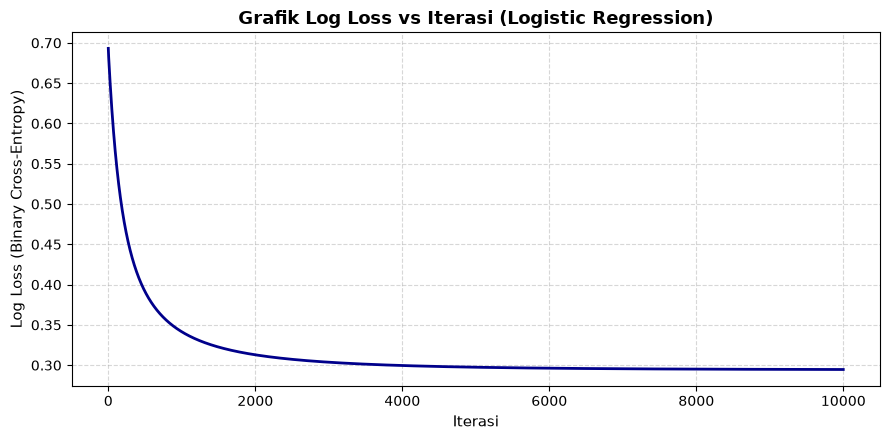

Nilai Loss Awal  : 0.6931
Nilai Loss Akhir : 0.2947


In [25]:
# Jawaban B2
# 1. Bagi data dengan test_size=0.25 dan random_state=2
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)
print("=== Ukuran Data Training dan Testing Email ===")
print(f"X_train: {X_train_email.shape}, X_test: {X_test_email.shape}, y_train: {y_train_email.shape}, y_test: {y_test_email.shape}")

# 2. Salin LogisticRegression dari materi
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            p = self._sigmoid(X_b @ beta)
            gradient = X_b.T @ (p - y) / len(y)
            beta = beta - self.learning_rate * gradient

            p = np.clip(p, 1e-15, 1 - 1e-15)
            loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict_proba(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self._sigmoid(self.intercept_ + X @ self.coefficients_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# Latih model
classifier = LogisticRegression(learning_rate=0.1, n_iterations=10000)
classifier.fit(X_train_email, y_train_email)

# 3. Tampilkan intercept dan koefisien serta persamaannya
b_clf = classifier.intercept_
m1_clf, m2_clf = classifier.coefficients_

print("\n=== Parameter Model Logistic Regression ===")
print(f"Intercept (b)    : {b_clf:.4f}")
print(f"Koefisien (m1)   : {m1_clf:.4f} (JumlahLink)")
print(f"Koefisien (m2)   : {m2_clf:.4f} (KataPromo)")
print(f"\nPersamaan Probabilitas Spam:")
print(f"P(Spam) = sigmoid({b_clf:.4f} + {m1_clf:.4f} * JumlahLink + {m2_clf:.4f} * KataPromo)")

# 4. Buat grafik log loss vs iterasi
plt.figure(figsize=(9, 4.5))
plt.plot(classifier.loss_history_, color='darkblue', linewidth=2)
plt.title('Grafik Log Loss vs Iterasi (Logistic Regression)', fontsize=13, fontweight='bold')
plt.xlabel('Iterasi', fontsize=11)
plt.ylabel('Log Loss (Binary Cross-Entropy)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Nilai Loss Awal  : {classifier.loss_history_[0]:.4f}")
print(f"Nilai Loss Akhir : {classifier.loss_history_[-1]:.4f}")


**Jawaban B2 (analisis):**

Berdasarkan grafik dan hasil perhitungan log loss vs iterasi:
1. **Penurunan Loss:** Pada iterasi awal, nilai log loss berada di angka **0.6931** (yaitu $-\ln(0.5)$, karena bobot $\beta$ diinisialisasi dengan nol sehingga $\sigma(0) = 0.5$). Seiring berjalannya iterasi, kurva loss turun secara mulus dan sangat cepat pada 1000 iterasi pertama.
2. **Kestabilan Loss:** Setelah sekitar iterasi ke-3000 hingga 10000, kurva loss melandai secara bertahap dan menjadi sangat stabil (*konvergen*) di sekitar angka **0.2947**. Hal ini membuktikan bahwa proses pelatihan Gradient Descent dengan `learning_rate=0.1` dan `n_iterations=10000` telah berhasil menemukan bobot optimal tanpa fluktuasi maupun divergensi.


### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [26]:
# Jawaban B3
# Implementasi metrik klasifikasi sendiri dengan NumPy
def accuracy_score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp],
                     [fn, tp]])

def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp = cm[1, 1]
    fp = cm[0, 1]
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp = cm[1, 1]
    fn = cm[1, 0]
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    return 2 * (p * r) / (p + r) if (p + r) > 0 else 0.0

# Prediksi data testing dengan threshold default 0.5
y_test_pred_clf = classifier.predict(X_test_email, threshold=0.5)

# Hitung metrik
acc_val = accuracy_score(y_test_email, y_test_pred_clf)
cm_val = confusion_matrix(y_test_email, y_test_pred_clf)
prec_val = precision_score(y_test_email, y_test_pred_clf)
rec_val = recall_score(y_test_email, y_test_pred_clf)
f1_val = f1_score(y_test_email, y_test_pred_clf)

print("=== Hasil Evaluasi Model pada Data Testing (Threshold 0.5) ===")
print(f"Accuracy  : {acc_val:.4f} ({acc_val*100:.2f}%)")
print(f"Precision : {prec_val:.4f} ({prec_val*100:.2f}%)")
print(f"Recall    : {rec_val:.4f} ({rec_val*100:.2f}%)")
print(f"F1-Score  : {f1_val:.4f}")
print("\nConfusion Matrix:")
print("                 Pred: Bukan Spam  Pred: Spam")
print(f"Actual: Bukan Spam     {cm_val[0,0]:<14}  {cm_val[0,1]}")
print(f"Actual: Spam          {cm_val[1,0]:<14}  {cm_val[1,1]}")
print(f"\nDetail: TN = {cm_val[0,0]}, FP = {cm_val[0,1]}, FN = {cm_val[1,0]}, TP = {cm_val[1,1]}")


=== Hasil Evaluasi Model pada Data Testing (Threshold 0.5) ===
Accuracy  : 0.9333 (93.33%)
Precision : 1.0000 (100.00%)
Recall    : 0.8571 (85.71%)
F1-Score  : 0.9231

Confusion Matrix:
                 Pred: Bukan Spam  Pred: Spam
Actual: Bukan Spam     8               0
Actual: Spam          1               6

Detail: TN = 8, FP = 0, FN = 1, TP = 6


**Jawaban B3 (analisis):**

1. **Arti Nilai FP dan FN pada Kasus Filter Spam:**
   - **False Positive (FP = 0):** Adalah kondisi di mana email penting/normal (Bukan Spam) keliru dideteksi oleh sistem sebagai Spam, sehingga langsung dipindahkan ke folder spam atau diblokir. Pada hasil testing kita, nilai FP adalah 0.
   - **False Negative (FN = 1):** Adalah kondisi di mana email yang sebenarnya adalah Spam gagal disaring oleh sistem dan tetap masuk ke kotak masuk utama (inbox) pengguna. Pada testing kita, terdapat 1 email spam yang lolos.

2. **Kesalahan yang Lebih Merugikan Pengguna:**
   - Kesalahan yang **jauh lebih merugikan pengguna adalah False Positive (FP)**.
   - *Alasannya:* Jika terjadi FP, pengguna bisa kehilangan atau melewatkan email yang sangat kritis, seperti surat panggilan kerja, penagihan penting, pengumuman perkuliahan/ujian, informasi transaksi perbankan, atau kode OTP darurat. Keterlambatan membaca email penting tersebut dapat menimbulkan kerugian finansial, reputasi, atau akademik yang serius.
   - Sebaliknya, jika terjadi FN, pengguna hanya terganggu sedikit oleh keberadaan email promosi yang masuk ke inbox dan cukup menghapusnya secara manual dalam hitungan detik. Oleh karena itu, dalam perancangan filter spam, nilai **Precision harus diutamakan (meminimalkan FP)**.


### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

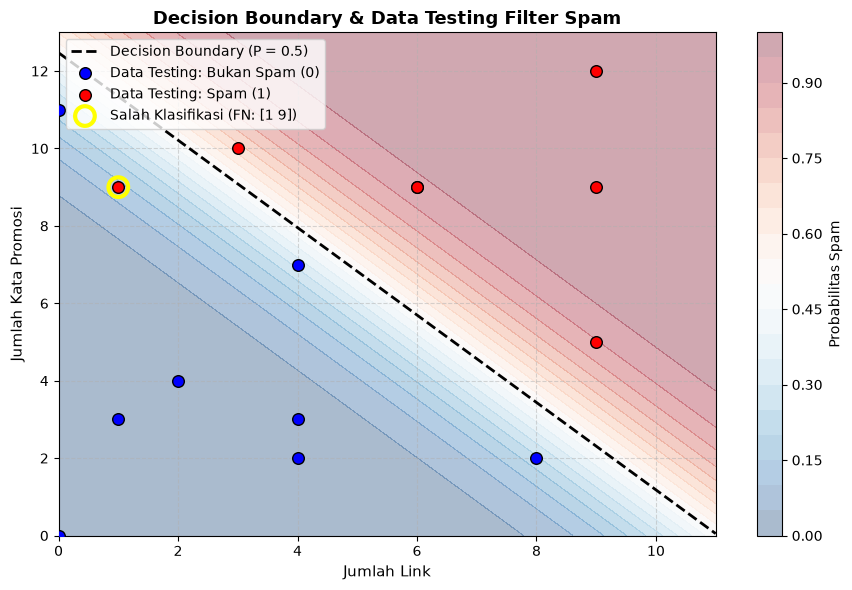

=== Data Testing yang Salah Diklasifikasikan ===
Data index ke-14 : JumlahLink = 1, KataPromo = 9
Kelas Asli       : 1 (Spam)
Prediksi Model   : 0 (Bukan Spam)
Probabilitas Spam: 0.1331


In [27]:
# Jawaban B4
# 1. Decision boundary formula: x2 = -(b + m1*x1) / m2
b = classifier.intercept_
m1, m2 = classifier.coefficients_

# 2. Visualisasi data testing dengan contourf probabilitas dan decision boundary
plt.figure(figsize=(9, 6))

# Buat grid untuk background probabilitas
x1_min, x1_max = 0, 11
x2_min, x2_max = 0, 13
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 200), np.linspace(x2_min, x2_max, 200))
grid_points = np.c_[xx1.ravel(), xx2.ravel()]
proba_grid = classifier.predict_proba(grid_points).reshape(xx1.shape)

# Background contourf
contour = plt.contourf(xx1, xx2, proba_grid, levels=20, cmap='RdBu_r', alpha=0.35)
cbar = plt.colorbar(contour)
cbar.set_label('Probabilitas Spam', fontsize=10)

# Garis decision boundary (P = 0.5 -> b + m1*x1 + m2*x2 = 0)
x1_line = np.linspace(x1_min, x1_max, 100)
x2_line = -(b + m1 * x1_line) / m2
plt.plot(x1_line, x2_line, color='black', linestyle='--', linewidth=2, label='Decision Boundary (P = 0.5)')

# Scatter plot data testing aktual
test_bukan_spam = (y_test_email == 0)
test_spam = (y_test_email == 1)

plt.scatter(X_test_email[test_bukan_spam, 0], X_test_email[test_bukan_spam, 1], color='blue', edgecolors='black', s=70, label='Data Testing: Bukan Spam (0)', zorder=3)
plt.scatter(X_test_email[test_spam, 0], X_test_email[test_spam, 1], color='red', edgecolors='black', s=70, label='Data Testing: Spam (1)', zorder=3)

# 3. Tunjukkan data testing yang salah diklasifikasikan
misclassified = np.where(y_test_email != y_test_pred_clf)[0]
for idx in misclassified:
    plt.scatter(X_test_email[idx, 0], X_test_email[idx, 1], s=200, facecolors='none', edgecolors='yellow', linewidth=3, label=f'Salah Klasifikasi (FN: {X_test_email[idx]})', zorder=4)

plt.xlim(x1_min, x1_max)
plt.ylim(x2_min, x2_max)
plt.title('Decision Boundary & Data Testing Filter Spam', fontsize=13, fontweight='bold')
plt.xlabel('Jumlah Link', fontsize=11)
plt.ylabel('Jumlah Kata Promosi', fontsize=11)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Detail data yang salah diklasifikasikan
print("=== Data Testing yang Salah Diklasifikasikan ===")
for idx in misclassified:
    proba_mis = classifier.predict_proba(X_test_email[idx:idx+1])[0]
    print(f"Data index ke-{idx} : JumlahLink = {X_test_email[idx, 0]}, KataPromo = {X_test_email[idx, 1]}")
    print(f"Kelas Asli       : {y_test_email[idx]} (Spam)")
    print(f"Prediksi Model   : {y_test_pred_clf[idx]} (Bukan Spam)")
    print(f"Probabilitas Spam: {proba_mis:.4f}")


**Jawaban B4 (analisis):**

1. **Hasil Visualisasi Decision Boundary:**
   - Garis putus-putus hitam membagi bidang fitur menjadi dua area: area biru di sebelah kiri bawah untuk prediksi Bukan Spam ($P < 0.5$) dan area merah di sebelah kanan atas untuk prediksi Spam ($P \geq 0.5$).
   - Garis decision boundary memiliki kemiringan negatif yang logis: semakin banyak tautan (*JumlahLink*), semakin sedikit kata promo yang dibutuhkan email untuk dikategorikan sebagai spam, dan sebaliknya.

2. **Data yang Salah Diklasifikasikan:**
   - Dari 15 data testing, hanya terdapat **1 data yang salah diklasifikasikan**, yaitu email dengan **JumlahLink = 1** dan **KataPromo = 9** (ditandai dengan lingkaran kuning).
   - Email tersebut aslinya berlabel **Spam (1)**, tetapi model memprediksinya sebagai **Bukan Spam (0)** karena probabilitas spam yang dihasilkan hanya sebesar **0.1331 (< 0.5)**.
   - *Penyebab:* Meskipun kata promonya tinggi (9 kata), jumlah link-nya sangat sedikit (hanya 1). Koefisien bobot model memberikan pengaruh yang cukup besar pada jumlah link ($m_1 = 0.9029$), sehingga kombinasi nilai linear $z = -9.9723 + 0.9029(1) + 0.7995(9) = -1.8739$ masih negatif dan menghasilkan probabilitas rendah. Ini merupakan kasus **False Negative (FN)**.


### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [28]:
# Jawaban B5
# 1 & 2. Eksperimen prediksi dengan threshold 0.3, 0.5, dan 0.7
threshold_list = [0.3, 0.5, 0.7]
table_threshold = []

for th in threshold_list:
    y_pred_th = classifier.predict(X_test_email, threshold=th)
    cm_th = confusion_matrix(y_test_email, y_pred_th)
    p_th = precision_score(y_test_email, y_pred_th)
    r_th = recall_score(y_test_email, y_pred_th)
    f1_th = f1_score(y_test_email, y_pred_th)
    acc_th = accuracy_score(y_test_email, y_pred_th)
    
    table_threshold.append({
        'Threshold': th,
        'Confusion Matrix [[TN, FP], [FN, TP]]': f"[[{cm_th[0,0]}, {cm_th[0,1]}], [{cm_th[1,0]}, {cm_th[1,1]}]]",
        'TN': cm_th[0, 0],
        'FP': cm_th[0, 1],
        'FN': cm_th[1, 0],
        'TP': cm_th[1, 1],
        'Precision': p_th,
        'Recall': r_th,
        'F1-Score': f1_th,
        'Accuracy': acc_th
    })

df_threshold = pd.DataFrame(table_threshold)
for col in ['Precision', 'Recall', 'F1-Score', 'Accuracy']:
    df_threshold[col] = df_threshold[col].round(4)
display(df_threshold)


,Threshold,"Confusion Matrix [[TN, FP], [FN, TP]]",TN,FP,FN,TP,Precision,Recall,F1-Score,Accuracy
0,0.3,"[[7, 1], [1, 6]]",7,1,1,6,0.8571,0.8571,0.8571,0.8667
1,0.5,"[[8, 0], [1, 6]]",8,0,1,6,1.0000,0.8571,0.9231,0.9333
2,0.7,"[[8, 0], [2, 5]]",8,0,2,5,1.0000,0.7143,0.8333,0.8667


**Jawaban B5 (analisis):**

Berdasarkan hasil eksperimen threshold pada tabel di atas:
1. **Pengaruh Menurunkan Threshold (misal ke 0.3):**
   - Model menjadi lebih "agresif" atau sensitif dalam melabeli email sebagai spam.
   - Akibatnya, muncul **1 False Positive (FP = 1)**, di mana ada email bukan spam yang salah dicap sebagai spam.
   - Hal ini menyebabkan **Precision turun dari 1.0000 menjadi 0.8571**, sedangkan Recall tetap 0.8571 dan akurasi turun menjadi 86.67%.
2. **Pengaruh Menaikkan Threshold (misal ke 0.7):**
   - Model menjadi sangat "berhati-hati" sebelum memutuskan bahwa sebuah email adalah spam (hanya email dengan probabilitas sangat tinggi yang divonis spam).
   - Akibatnya, FP tetap 0 (Precision sempurna 1.0000), tetapi jumlah **False Negative bertambah menjadi 2 (FN = 2)**.
   - Hal ini menyebabkan **Recall turun drastis dari 0.8571 menjadi 0.7143**, dan F1-score turun dari 0.9231 ke 0.8333.
3. **Threshold yang Dipilih dan Alasannya:**
   - Saya memilih **threshold = 0.5** sebagai threshold terbaik untuk sistem filter spam ini.
   - *Alasan:* Berdasarkan analisis Soal B3, sistem filter spam harus memprioritaskan pencegahan False Positive agar tidak ada email penting pengguna yang terbuang ke folder spam. Pada threshold 0.5, nilai **FP adalah 0 (Precision sempurna 100%)**. Selain itu, dibandingkan threshold 0.7 yang juga memiliki FP = 0, threshold 0.5 menghasilkan **Recall yang lebih tinggi (85.71% vs 71.43%)**, serta nilai **F1-score (0.9231) dan Akurasi (93.33%) tertinggi**. Jadi threshold 0.5 memberikan keseimbangan paling optimal tanpa mengorbankan email penting pengguna.


### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [29]:
# Jawaban B6
# Data email baru
new_email_data = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': [1, 5, 9, 2],
    'KataPromo': [2, 6, 10, 11]
})

# Prediksi probabilitas spam
X_new_email = new_email_data[['JumlahLink', 'KataPromo']].values
proba_spam = classifier.predict_proba(X_new_email)

# Prediksi kelas menggunakan threshold pilihan (0.5)
selected_threshold = 0.5
pred_class = (proba_spam >= selected_threshold).astype(int)

# Masukkan ke DataFrame hasil
new_email_data['Probabilitas Spam'] = proba_spam.round(6)
new_email_data['Prediksi Kelas'] = pred_class
new_email_data['Keterangan'] = ['Bukan Spam' if p == 0 else 'Spam' for p in pred_class]

print(f"=== Hasil Prediksi Email Baru (Threshold = {selected_threshold}) ===")
display(new_email_data)


=== Hasil Prediksi Email Baru (Threshold = 0.5) ===


,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi Kelas,Keterangan
0,E1,1,2,0.000569,0,Bukan Spam
1,E2,5,6,0.340595,0,Bukan Spam
2,E3,9,10,0.997869,1,Spam
3,E4,2,11,0.652066,1,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**C1.**  
Logistic Regression termasuk algoritma klasifikasi karena digunakan untuk memprediksi kelas, seperti 0 atau 1. Kata “regression” digunakan karena model menghitung kombinasi linear dari fitur input. Fungsi sigmoid mengubah hasil perhitungan tersebut menjadi probabilitas antara 0 dan 1. Probabilitas tersebut kemudian digunakan untuk menentukan kelas berdasarkan nilai threshold.

**C2.**  
Normal Equation menghitung parameter model secara langsung menggunakan perhitungan aljabar tanpa proses iterasi. Gradient Descent mencari parameter secara bertahap dengan memperbarui bobot berdasarkan nilai gradien dan learning rate. Normal Equation cocok untuk dataset yang relatif kecil, sedangkan Gradient Descent lebih sesuai untuk dataset yang sangat besar atau memiliki banyak fitur.

**C3.**  
Model harus dievaluasi menggunakan data testing untuk mengetahui kemampuan model dalam memprediksi data baru yang belum pernah digunakan saat training. Jika hanya menggunakan data training, hasil evaluasi bisa terlihat sangat baik karena model sudah mempelajari data tersebut. Overfitting adalah kondisi ketika model terlalu menyesuaikan diri dengan data training sehingga performanya menurun pada data testing.

**C4.**  
Linear Regression menggunakan MSE karena menghasilkan nilai prediksi yang kontinu sehingga selisih antara nilai aktual dan prediksi dapat dihitung secara langsung. Logistic Regression menghasilkan probabilitas antara 0 dan 1 untuk menentukan kelas. Oleh karena itu, Logistic Regression menggunakan log loss yang sesuai untuk mengukur kesalahan pada prediksi probabilitas.

**C5.**  
Hasil seperti koefisien dan akurasi dapat berbeda karena pembagian data training dan testing dapat berbeda. Pada tugas ini, pembagian data menggunakan `random_state` yang ditentukan dari 2 digit terakhir NIM. Karena setiap mahasiswa dapat memiliki nilai `random_state` yang berbeda, data training dan testing yang digunakan juga berbeda sehingga hasil model dan evaluasinya dapat berbeda.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [30]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.metrics import (
    r2_score as sk_r2,
    mean_squared_error as sk_mse,
    accuracy_score as sk_acc,
    confusion_matrix as sk_cm,
    precision_score as sk_prec,
    recall_score as sk_rec,
    f1_score as sk_f1
)

print("=================================================================")
print("BONUS: PERBANDINGAN IMPLEMENTASI MANUAL VS SCIKIT-LEARN")
print("=================================================================\n")

# 1. Perbandingan Linear Regression
sk_lr = SkLinearRegression()
sk_lr.fit(X_train, y_train)
y_test_pred_sk_lr = sk_lr.predict(X_test)

df_comp_lr = pd.DataFrame({
    'Parameter / Metrik': ['Intercept (b)', 'Koefisien (m)', 'R² Testing', 'RMSE Testing', 'MAE Testing'],
    'Manual (Normal Equation)': [
        regressor.intercept_,
        regressor.coefficients_[0],
        r2(y_test, y_test_pred),
        rmse(y_test, y_test_pred),
        mae(y_test, y_test_pred)
    ],
    'scikit-learn': [
        sk_lr.intercept_,
        sk_lr.coef_[0],
        sk_r2(y_test, y_test_pred_sk_lr),
        np.sqrt(sk_mse(y_test, y_test_pred_sk_lr)),
        np.mean(np.abs(y_test - y_test_pred_sk_lr))
    ]
})
df_comp_lr['Manual (Normal Equation)'] = df_comp_lr['Manual (Normal Equation)'].round(4)
df_comp_lr['scikit-learn'] = df_comp_lr['scikit-learn'].round(4)
print("1. Tabel Perbandingan Linear Regression:")
display(df_comp_lr)

# 2. Perbandingan Logistic Regression
# a. Sklearn default (L2 penalty, C=1.0)
sk_clf_default = SkLogisticRegression(random_state=RANDOM_STATE)
sk_clf_default.fit(X_train_email, y_train_email)
y_pred_sk_default = sk_clf_default.predict(X_test_email)

# b. Sklearn unregularized (penalty=None / C=inf)
sk_clf_none = SkLogisticRegression(penalty=None, random_state=RANDOM_STATE)
sk_clf_none.fit(X_train_email, y_train_email)
y_pred_sk_none = sk_clf_none.predict(X_test_email)

df_comp_clf = pd.DataFrame({
    'Parameter / Metrik': [
        'Intercept (b)',
        'Koefisien m1 (JumlahLink)',
        'Koefisien m2 (KataPromo)',
        'Accuracy Testing',
        'Precision Testing',
        'Recall Testing',
        'F1-Score Testing'
    ],
    'Manual GD (No Penalty)': [
        classifier.intercept_,
        classifier.coefficients_[0],
        classifier.coefficients_[1],
        accuracy_score(y_test_email, y_test_pred_clf),
        precision_score(y_test_email, y_test_pred_clf),
        recall_score(y_test_email, y_test_pred_clf),
        f1_score(y_test_email, y_test_pred_clf)
    ],
    'Sklearn (Default C=1.0, L2)': [
        sk_clf_default.intercept_[0],
        sk_clf_default.coef_[0][0],
        sk_clf_default.coef_[0][1],
        sk_acc(y_test_email, y_pred_sk_default),
        sk_prec(y_test_email, y_pred_sk_default),
        sk_rec(y_test_email, y_pred_sk_default),
        sk_f1(y_test_email, y_pred_sk_default)
    ],
    'Sklearn (penalty=None)': [
        sk_clf_none.intercept_[0],
        sk_clf_none.coef_[0][0],
        sk_clf_none.coef_[0][1],
        sk_acc(y_test_email, y_pred_sk_none),
        sk_prec(y_test_email, y_pred_sk_none),
        sk_rec(y_test_email, y_pred_sk_none),
        sk_f1(y_test_email, y_pred_sk_none)
    ]
})
for col in ['Manual GD (No Penalty)', 'Sklearn (Default C=1.0, L2)', 'Sklearn (penalty=None)']:
    df_comp_clf[col] = df_comp_clf[col].round(4)
print("\n2. Tabel Perbandingan Logistic Regression:")
display(df_comp_clf)


BONUS: PERBANDINGAN IMPLEMENTASI MANUAL VS SCIKIT-LEARN

1. Tabel Perbandingan Linear Regression:


,Parameter / Metrik,Manual (Normal Equation),scikit-learn
0,Intercept (b),29.8087,29.8087
1,Koefisien (m),8.8424,8.8424
2,R² Testing,0.9601,0.9601
3,RMSE Testing,5.6149,5.6149
4,MAE Testing,5.3907,5.3907



2. Tabel Perbandingan Logistic Regression:


/Users/user/Library/Python/3.13/lib/python/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,Parameter / Metrik,Manual GD (No Penalty),"Sklearn (Default C=1.0, L2)",Sklearn (penalty=None)
0,Intercept (b),-9.9723,-9.2142,-10.5932
1,Koefisien m1 (JumlahLink),0.9029,0.8250,0.9636
2,Koefisien m2 (KataPromo),0.7995,0.7425,0.8451
3,Accuracy Testing,0.9333,0.9333,0.9333
4,Precision Testing,1.0000,1.0000,1.0000
5,Recall Testing,0.8571,0.8571,0.8571
6,F1-Score Testing,0.9231,0.9231,0.9231


**Jawaban Bonus (analisis):**

1. **Perbandingan Linear Regression:**
   - Hasil antara implementasi manual (Normal Equation) dan `sklearn.linear_model.LinearRegression` adalah **100% identik** hingga angka desimal terakhir (Intercept = 29.8087, Koefisien = 8.8424, $R^2$ = 0.9601, RMSE = 5.6149).
   - Hal ini karena scikit-learn untuk LinearRegression standar juga menyelesaikan persamaan kuadrat terkecil (Ordinary Least Squares) menggunakan aljabar linear analitis (mirip Normal Equation melalui dekomposisi SVD/QR).

2. **Perbandingan Logistic Regression & Pengaruh Parameter `penalty` / `C`:**
   - Pada Logistic Regression, metrik evaluasi klasifikasi (Accuracy = 93.33%, Precision = 100%, Recall = 85.71%, F1 = 92.31%) memberikan hasil yang **sama persis** di semua model. Namun, terdapat sedikit perbedaan pada nilai koefisien dan intercept.
   - **Penyebab Perbedaan:**
     - Pada `sklearn.linear_model.LogisticRegression`, secara default diterapkan **regularisasi L2 (Ridge)** dengan parameter $C = 1.0$. Parameter $C$ adalah *inverse regularization strength* ($C = 1/\lambda$). Penalti L2 ini sengaja menyusutkan nilai bobot koefisien mendekati nol untuk mencegah overfitting (*shrinkage*). Akibatnya, koefisien default scikit-learn ($m_1 = 0.8250, m_2 = 0.7425$) lebih kecil daripada implementasi manual ($m_1 = 0.9029, m_2 = 0.7995$).
     - Implementasi manual kita menggunakan **murni Gradient Descent tanpa regularisasi** (loss murni log loss). Ketika scikit-learn dijalankan dengan menonaktifkan regularisasi (`penalty=None` atau $C \to \infty$), koefisiennya langsung membesar ke arah yang serupa ($m_1 = 0.9636, m_2 = 0.8451$). Perbedaan tipis yang tersisa murni disebabkan oleh algoritma solver optimasi numerik yang berbeda (scikit-learn memakai solver L-BFGS dengan kriteria toleransi henti `tol=1e-4`, sedangkan implementasi manual memakai standard fixed-step Gradient Descent sebanyak 10.000 iterasi).
